# Bank Loan Approval Prediction using Logistic Regression
This notebook implements a Logistic Regression model using scikit-learn's default settings (no penalty or regularisation strength is specified). It prevents data leakage during scaling, removes irrelevant identifiers, one-hot encodes categorical variables, and selects features with explicit correlation rules (weak correlation with the target, or near-duplicate of another feature).

**Outline**
1. Load the dataset
2. Feature correlation analysis (correlation plot, heatmap, selection rules)
3. Pre-processing and feature selection
4. Train / test split and normalisation
5. Functions for training and testing the model
6. Training plots (learning curve, validation loss curve)
7. Evaluation metrics (Confusion Matrix, Accuracy, Precision, Recall, F1, RMSE, ROC AUC)

**Team split** (every section is tagged *Part 1-4* below; lines of code = non-blank, non-comment code lines)
| Part | Owner | What they own | Lines of code |
|---|---|---|---:|
| Part 1 | ________ | Imports, 1 Load the dataset, 2 correlation plot, 2.1 heatmap, 2.2 Rule 1 (weak predictors) | 39 |a
| Part 2 | ________ | 2.3 Rule 2 (redundant features), 3 pre-processing, 4 split, 4.1 normalisation, 5.1 training function | 44 |
| Part 3 | ________ | 5.2 train the model, 5.3 testing function, 6.1 learning curve, 6.2 validation loss curve | 38 |
| Part 4 | ________ | 7.1 train vs test metrics, 7.2 confusion-matrix function and confusion matrix, 7.3 classification report, 7.4 ROC curve and coefficients | 42 |

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, learning_curve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix, precision_score, recall_score,
    f1_score, accuracy_score, mean_squared_error,
    roc_curve, auc, roc_auc_score, classification_report
)

sns.set_theme(style="whitegrid")

> *Part 1*

## 1. Load the Dataset
The target variable is `Personal.Loan`.

In [25]:
# Load dataset
df = pd.read_csv('../data/bankloan.csv')
display(df.head())
display(df.info())

,ID,Age,Experience,Income,ZIP.Code,Family,CCAvg,Education,Mortgage,Personal.Loan,Securities.Account,CD.Account,Online,CreditCard
0,1,25,1,49,91107,4,1.6,1,0,0,1,0,0,0
1,2,45,19,34,90089,3,1.5,1,0,0,1,0,0,0
2,3,39,15,11,94720,1,1.0,1,0,0,0,0,0,0
3,4,35,9,100,94112,1,2.7,2,0,0,0,0,0,0
4,5,35,8,45,91330,4,1.0,2,0,0,0,0,0,1


<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ID                  5000 non-null   int64  
 1   Age                 5000 non-null   int64  
 2   Experience          5000 non-null   int64  
 3   Income              5000 non-null   int64  
 4   ZIP.Code            5000 non-null   int64  
 5   Family              5000 non-null   int64  
 6   CCAvg               5000 non-null   float64
 7   Education           5000 non-null   int64  
 8   Mortgage            5000 non-null   int64  
 9   Personal.Loan       5000 non-null   int64  
 10  Securities.Account  5000 non-null   int64  
 11  CD.Account          5000 non-null   int64  
 12  Online              5000 non-null   int64  
 13  CreditCard          5000 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 547.0 KB


None

> *Part 1*

## 2. Feature Correlation Analysis
Features are selected with two explicit rules based on the Pearson correlation coefficient:
1. **Weak predictor:** a feature whose absolute correlation with `Personal.Loan` is below `0.05` is dropped.
2. **Redundant feature:** if two features have an absolute correlation above `0.8` with each other, only one of the two is kept.

`ID` and `ZIP.Code` are identifiers (they are dropped in the next section), so they are left out of the correlation plot.

C:\Users\Abhishek\AppData\Local\Temp\ipykernel_13828\3791815473.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=target_corr.values, y=target_corr.index, palette='coolwarm')


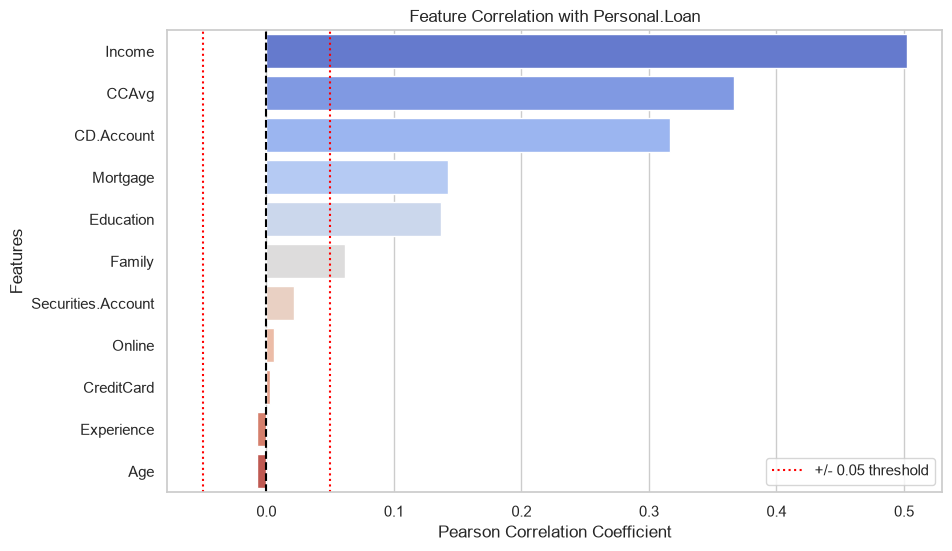

Correlation Values:
 Income                0.502462
CCAvg                 0.366889
CD.Account            0.316355
Mortgage              0.142095
Education             0.136722
Family                0.061367
Securities.Account    0.021954
Online                0.006278
CreditCard            0.002802
Experience           -0.007413
Age                  -0.007726
Name: Personal.Loan, dtype: float64


In [26]:
# Selection thresholds
CORR_THRESHOLD = 0.05        # |correlation with target| below this = weak predictor
COLLINEAR_THRESHOLD = 0.8    # |correlation between two features| above this = redundant pair
identifiers = ['ID', 'ZIP.Code']

# Correlation of every feature with the target (identifiers excluded)
corr_matrix = df.corr(numeric_only=True)
target_corr = corr_matrix['Personal.Loan'].drop(['Personal.Loan'] + identifiers).sort_values(ascending=False)

# Plot the correlations with the selection threshold
plt.figure(figsize=(10, 6))
sns.barplot(x=target_corr.values, y=target_corr.index, palette='coolwarm')
plt.title("Feature Correlation with Personal.Loan")
plt.xlabel("Pearson Correlation Coefficient")
plt.ylabel("Features")
plt.axvline(x=0, color='black', linestyle='--')
plt.axvline(x=CORR_THRESHOLD, color='red', linestyle=':', label=f'+/- {CORR_THRESHOLD} threshold')
plt.axvline(x=-CORR_THRESHOLD, color='red', linestyle=':')
plt.legend()
plt.show()

print("Correlation Values:\n", target_corr)

> *Part 1*

### 2.1 Correlation heatmap
The heatmap shows the correlation between every pair of features (identifiers excluded). The bright cell for `Age` and `Experience` is the near-duplicate pair examined by Rule 2 below.

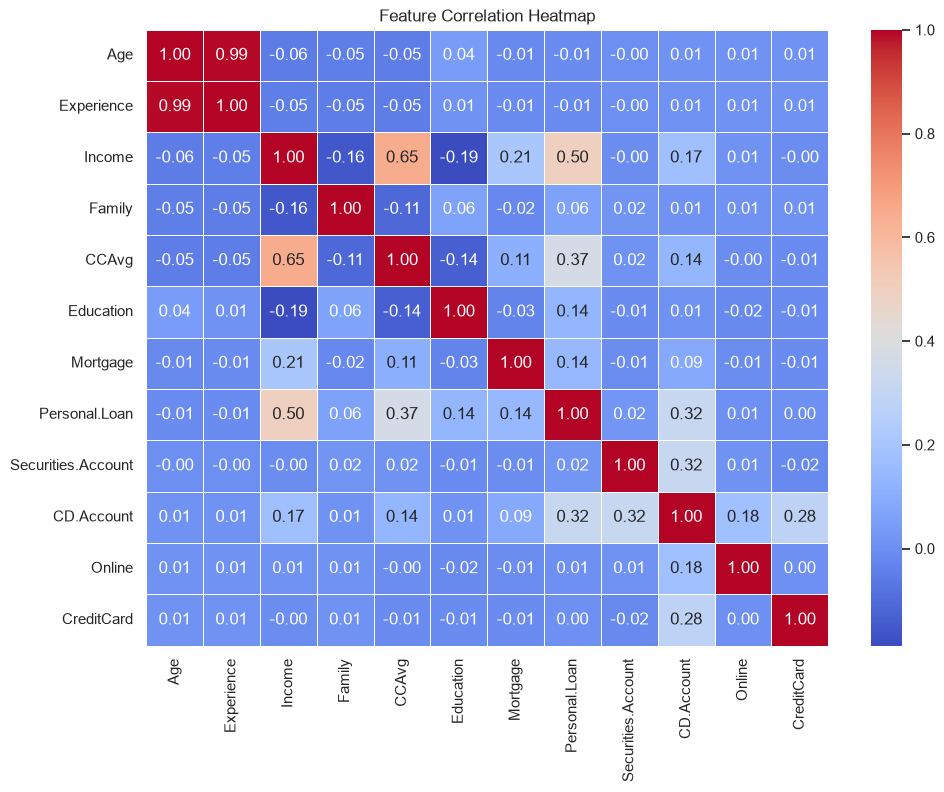

In [27]:
plt.figure(figsize=(11, 8))
sns.heatmap(corr_matrix.drop(index=identifiers, columns=identifiers), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title("Feature Correlation Heatmap")
plt.show()

> *Part 1*

### 2.2 Rule 1 - weak predictors
A feature whose absolute correlation with `Personal.Loan` is below `0.05` carries almost no linear information about the target, so it is marked for removal.

In [28]:
weak_features = target_corr.index[target_corr.abs() < CORR_THRESHOLD].tolist()
print(f"Rule 1 - weak predictors (|r| < {CORR_THRESHOLD}): {weak_features}")

Rule 1 - weak predictors (|r| < 0.05): ['Securities.Account', 'Online', 'CreditCard', 'Experience', 'Age']
